In [ ]:
# Customer Churn Intelligence and Retention Recommendation System

## Problem Statement

Customer churn occurs when customers stop using a company's services. Losing customers can reduce revenue and increase the cost of acquiring replacements. This project aims to develop an end-to-end machine learning application that estimates customer churn risk using customer demographics, subscription details, service usage attributes, and billing information.

## Objectives

1. Explore and clean customer data.
2. Train and compare classification models.
3. Evaluate model performance using precision, recall, F1-score, ROC-AUC, and PR-AUC.
4. Explain predictions using feature importance and SHAP.
5. Build an interactive Streamlit dashboard for customer risk analysis.
6. Recommend potential retention actions using interpretable business rules.
7. Estimate potential campaign value using explicit financial assumptions.

## Dataset

The project uses a publicly available IBM Telco Customer Churn dataset. The target variable is `Churn`, which indicates whether a customer churned in the recorded data.

## Expected Deliverables

- Reproducible data analysis and ML training notebooks
- A saved preprocessing and prediction pipeline
- Model evaluation and explainability reports
- An interactive customer churn dashboard
- A documented GitHub repository

## Limitations

The dataset is a learning dataset and does not establish that the model will generalize to every telecom company. Predictions indicate estimated risk, not certainty. Retention recommendations and financial estimates require validation using real business data.


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

pd.set_option("display.max_columns",None)
pd.set_option("display.max_rows",20)

print("Libraries imported successfully.")

Libraries imported successfully.


In [7]:
data_path = Path(r"C:\customer-churn-intelligence\data\raw\WA_Fn-UseC_-Telco-Customer-Churn.csv")

if not data_path.exists():
    raise FileNotFoundError(
        f"Dataset not found at: {data_path}"
    )

df = pd.read_csv(data_path)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [8]:
df.shape

(7043, 21)

In [9]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [10]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("Dataset shape:", df.shape)

Number of rows: 7043
Number of columns: 21
Dataset shape: (7043, 21)


In [11]:
print(df.columns.tolist())

['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [13]:
print(df["Churn"].value_counts())

Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [14]:
churn_percentage = (df["Churn"].value_counts(normalize=True) * 100)
print(churn_percentage.round(2))

Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


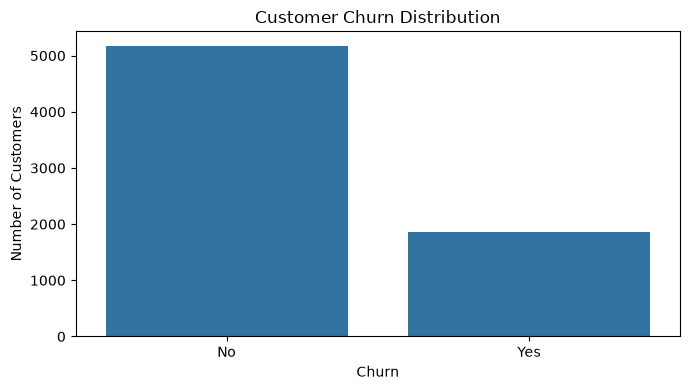

In [15]:
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="Churn")
plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

In [16]:
missing_values = df.isnull().sum()

print(missing_values[missing_values > 0].sort_values(ascending=False))

Series([], dtype: int64)


In [17]:
print("Duplicate rows:", df.duplicated().sum())

print("Duplicate customer IDs:",df["customerID"].duplicated().sum())

Duplicate rows: 0
Duplicate customer IDs: 0


In [18]:
print("TotalCharges data type:", df["TotalCharges"].dtype)

blank_total_charges = (df["TotalCharges"].astype(str).str.strip().eq("").sum())

print("Blank TotalCharges values:", blank_total_charges)

TotalCharges data type: str
Blank TotalCharges values: 11


In [19]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [20]:
for column in [
    "gender",
    "Contract",
    "InternetService",
    "PaymentMethod",
    "Churn"
]:
    print(f"\n--- {column} ---")
    print(df[column].value_counts(dropna=False))


--- gender ---
gender
Male      3555
Female    3488
Name: count, dtype: int64

--- Contract ---
Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64

--- InternetService ---
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

--- PaymentMethod ---
PaymentMethod
Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: count, dtype: int64

--- Churn ---
Churn
No     5174
Yes    1869
Name: count, dtype: int64
